# Geographic and Account Behaviour Fraud Analytics

**PBI 7, Task #64 (Yue Liang)** - individual business analytics for SP-buy Trust & Safety analysts.

This notebook presents the results of three analytical queries on the latest labelled orders in the team's AWS RDS database. It does not contain a second copy of the analysis: all queries, calculations and charts come from `src/analytics_geo_account_yueliang.py`, which the Prefect flow `flows/geo_account_risk_flow_yueliang.py` also runs. Keeping the logic in one place means the notebook, the flow and the report can never disagree.

| Question | Investigation decision it supports |
|---|---|
| Q1 Which countries have the highest fraud rates and fraudulent transaction volumes? | Which geographic segments need closer investigation |
| Q2 Do customers with more associated customer accounts have higher fraud rates? | Whether linked-account activity should be used to prioritise suspicious accounts |
| Q3 Does a higher cancellation rate over the last 50 days correspond to a higher fraud rate? | Whether unusually frequent cancellations warrant further investigation |

## Setup

`RUN_LIVE = False` shows the outputs saved by the most recent run of the script or Prefect flow (no database connection needed).

`RUN_LIVE = True` re-runs all three queries against RDS now (about one minute). This needs `DB_HOST`, `DB_USER` and `DB_PASSWORD` set as environment variables in the terminal that started Jupyter or VS Code; credentials are never written in the notebook.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))
import analytics_geo_account_yueliang as analytics

RUN_LIVE = False
OUTPUT_DIR = REPO_ROOT / "outputs" / "analytics_yueliang"

if RUN_LIVE:
    analytics.run_analysis(OUTPUT_DIR)

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)


def table(name, columns=None):
    frame = pd.read_csv(OUTPUT_DIR / f"{name}.csv")
    return frame[columns] if columns else frame


def chart(name):
    display(Image(filename=str(OUTPUT_DIR / f"{name}.png")))


RATE = ["orders", "frauds", "fraud_rate_pct", "ci_low_pct", "ci_high_pct", "lift"]
SHARES = ["share_of_orders_pct", "share_of_fraud_pct"]

## Data used and how to read the results

- **Unit of analysis:** one labelled order (`fraud_labels` joined to its order and customer on `country_code` plus ID).
- **Fraud rate:** fraud orders / orders in the group. Every group is compared with the overall fraud rate.
- **95% CI:** Wilson confidence interval. A wide interval means the group is too small to be sure of its rate.
- **Lift:** the group's fraud rate divided by the overall fraud rate (2.0 = twice as likely to be fraud).
- **Share of orders vs share of fraud:** analysts have limited time, so these show how much review effort a group needs and how much of all fraud it would catch.

The status lines and findings below are recomputed from the data every time the analysis runs.

In [2]:
summary = (OUTPUT_DIR / "summary.md").read_text(encoding="utf-8")
display(Markdown(summary.split("## Q1")[0]))

# Geographic and account behaviour fraud analytics

- Generated: 2026-11-28 20:51
- Labelled orders analysed: 949,969 (104,433 fraud, 11.0%)
- Order dates: 2022-11-12 to 2023-05-11
- ETL batches in RDS: base (completed), test (completed)



## Q1 Which countries have the highest fraud rates and fraudulent transaction volumes?

**Investigation decision:** which geographic segments require closer investigation.

**Method:** fraud rate (with 95% CI), number and share of fraud orders, and the SGD value of fraud orders per country. The latest 4 order weeks are compared with the earlier period to show whether a country is getting worse; the newest week can be incomplete.

Rate and volume answer different questions: the rate says how risky each order from a country is (how strict checks should be), while the volume says where most fraud actually happens (where most review hours should go).

In [3]:
table("q1_countries", ["country"] + RATE + ["share_of_orders_pct", "share_of_fraud_pct", "fraud_order_value",
                                       "share_of_fraud_value_pct", "earlier_fraud_rate_pct",
                                       "recent_fraud_rate_pct", "change_pp"])

,country,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,lift,share_of_orders_pct,share_of_fraud_pct,fraud_order_value,share_of_fraud_value_pct,earlier_fraud_rate_pct,recent_fraud_rate_pct,change_pp
0,Bangladesh,59564,17436,29.27,28.91,29.64,2.66,6.27,16.70,"88,001.71",10.82,27.69,39.78,12.09
1,Pakistan,184843,45322,24.52,24.32,24.72,2.23,19.46,43.40,"256,853.63",31.59,24.61,24.03,-0.58
2,Philippines,281225,23827,8.47,8.37,8.58,0.77,29.60,22.82,"231,752.63",28.50,8.65,7.42,-1.23
3,Thailand,63731,3803,5.97,5.79,6.15,0.54,6.71,3.64,"60,047.37",7.39,5.93,6.19,0.26
4,Malaysia,360606,14045,3.90,3.83,3.96,0.35,37.96,13.45,"176,357.42",21.69,3.76,4.98,1.21


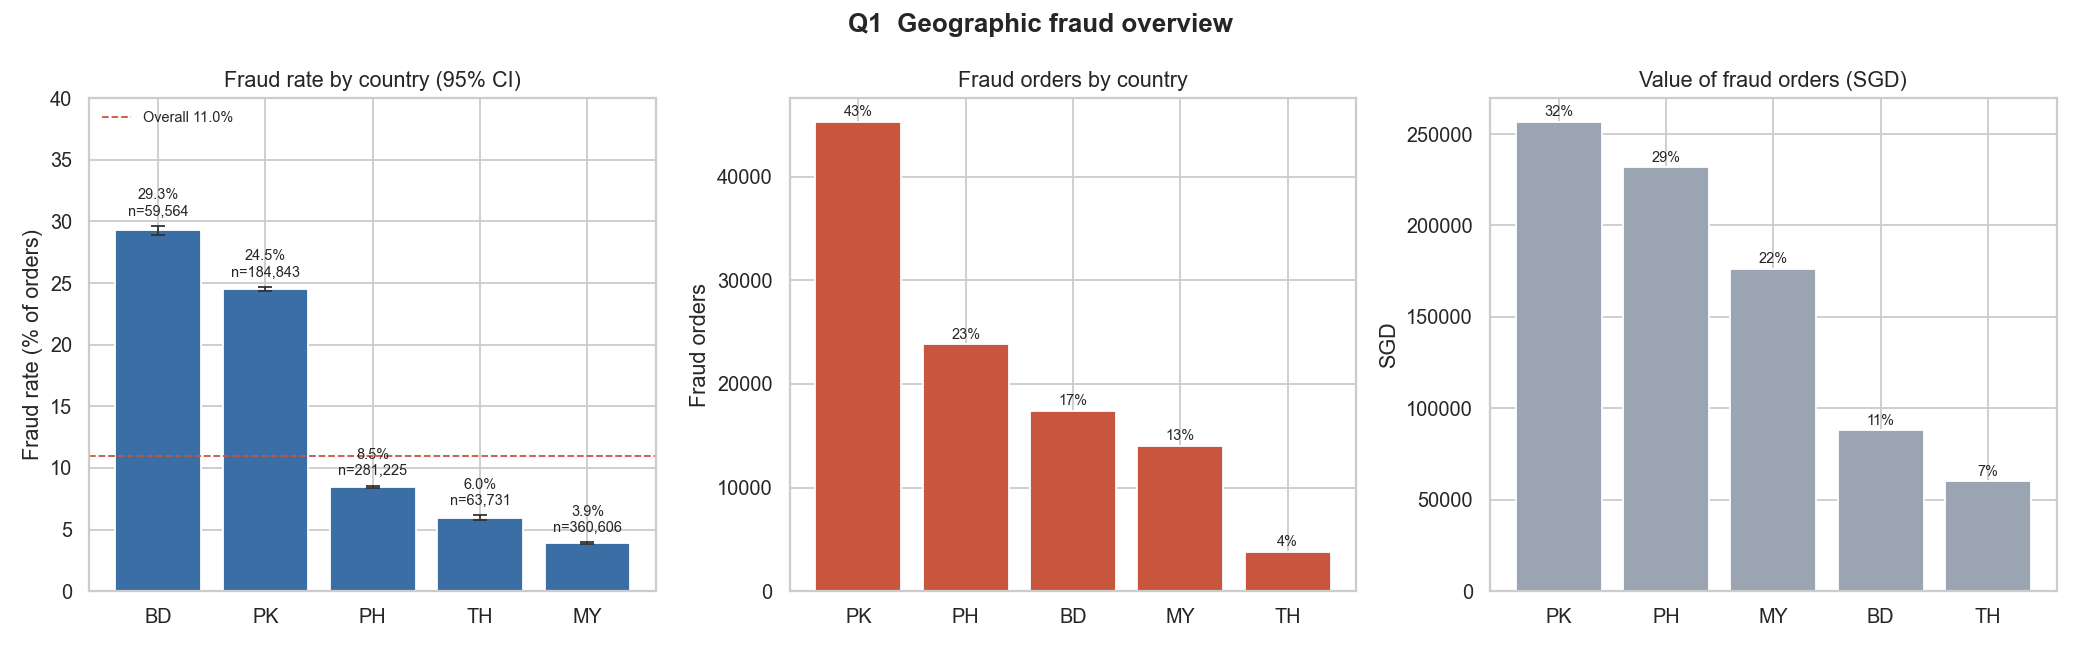

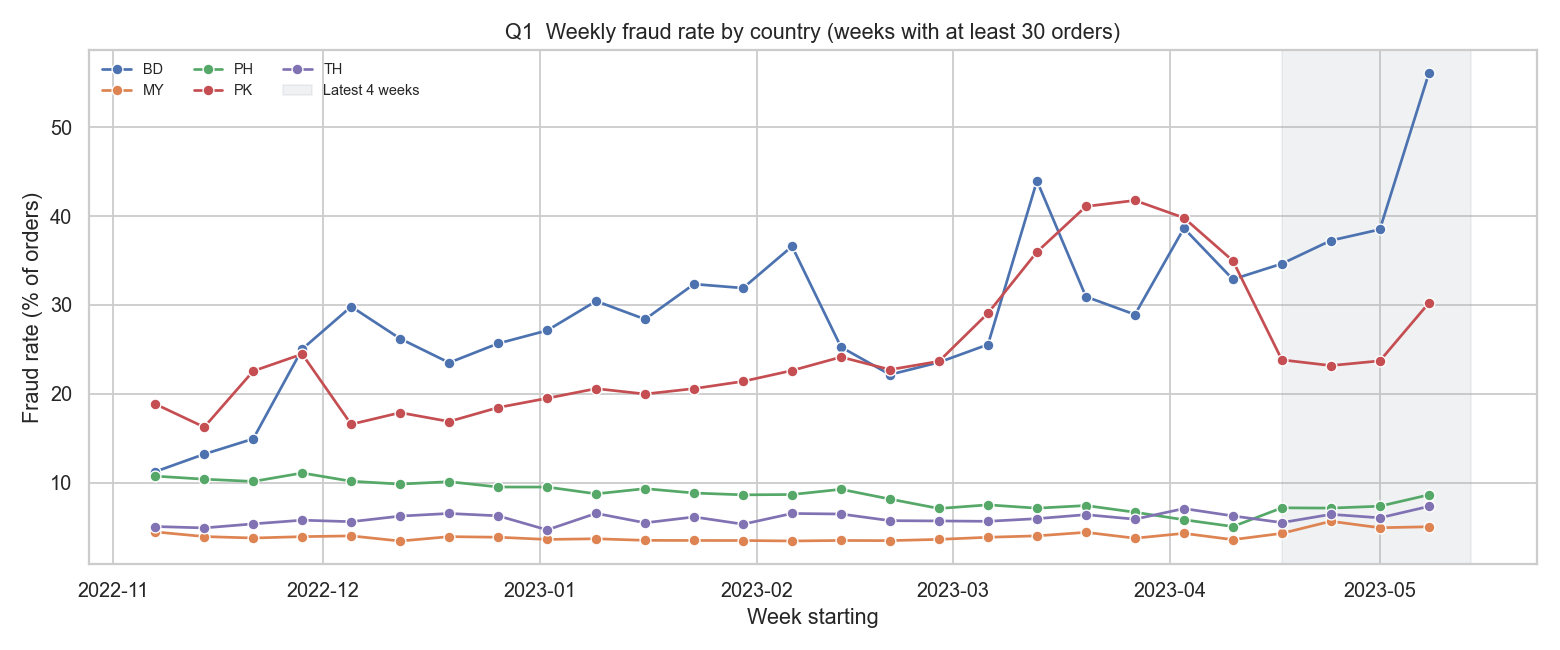

In [4]:
chart("q1_country_overview")
chart("q1_weekly_trend")

### Q1 insights (run of 28 Nov 2026: 949,969 labelled orders, overall fraud rate 11.0%)

- **Only two countries are above the overall rate: Bangladesh (29.3%, 2.66x) and Pakistan (24.5%, 2.23x).** The other three are well below it: Philippines 8.5%, Thailand 6.0% and Malaysia 3.9%.
- **Pakistan has the largest fraud volume:** 45,322 fraud orders, **43.4% of all fraud from only 19.5% of orders**, and the largest value of fraud orders (SGD 256,854, 31.6% of the total).
- **Bangladesh is getting worse:** its rate rose from 27.7% to 39.8% in the latest 4 weeks (+12.1 percentage points). The last weekly point covers only 4 days, but the three full weeks before it were also above its earlier level, so the rise is not caused by that one short week.
- **The Philippines has a below-average rate but high volume:** 8.5% is under the overall rate, yet because it has many orders it still accounts for 22.8% of all fraud and 28.5% of the fraud value.

**Investigation decision:**
- Bangladesh: apply stricter checks to its orders now and monitor its weekly rate, because both its level and its trend are the worst.
- Pakistan: give it the largest share of review capacity, because that is where the most fraud cases and money are.
- Philippines: do not tighten country-level checks (most of its orders are genuine), but rely on account-level signals such as Q2 and Q3 to find its fraud.
- Thailand and Malaysia: standard checks.

The two countries need different actions, which is why the analysis reports rate and volume separately.

## Q2 Do customers with more associated customer accounts have higher fraud rates?

**Investigation decision:** whether linked-account activity should be considered when prioritising suspicious accounts.

**Method:** orders are grouped by the customer's number of associated accounts into the bands 1-3, 4-5, 6-8, 9-19, 20-99 and 100+. The bands come from the distribution in RDS: 1-3 links are at or below the overall rate, the rate roughly doubles from 6 links and passes 50% from 9 links, and single values above 20 hold too few orders to be reliable. The source data caps the count at 100 (cleaning Assumption 12).

A review list gives the confirmed-fraud accounts with at least 9 associated accounts, whose linked accounts are the next ones to check.

In [5]:
table("q2_associated_bands", ["segment"] + RATE + SHARES)

,segment,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,lift,share_of_orders_pct,share_of_fraud_pct
0,1-3,772069,65191,8.44,8.38,8.51,0.77,81.27,62.42
1,4-5,105791,11416,10.79,10.61,10.98,0.98,11.14,10.93
2,6-8,43031,11334,26.34,25.93,26.76,2.40,4.53,10.85
3,9-19,19875,10761,54.14,53.45,54.84,4.92,2.09,10.30
4,20-99,6633,3912,58.98,57.79,60.16,5.37,0.70,3.75
5,100+,2570,1819,70.78,68.99,72.50,6.44,0.27,1.74


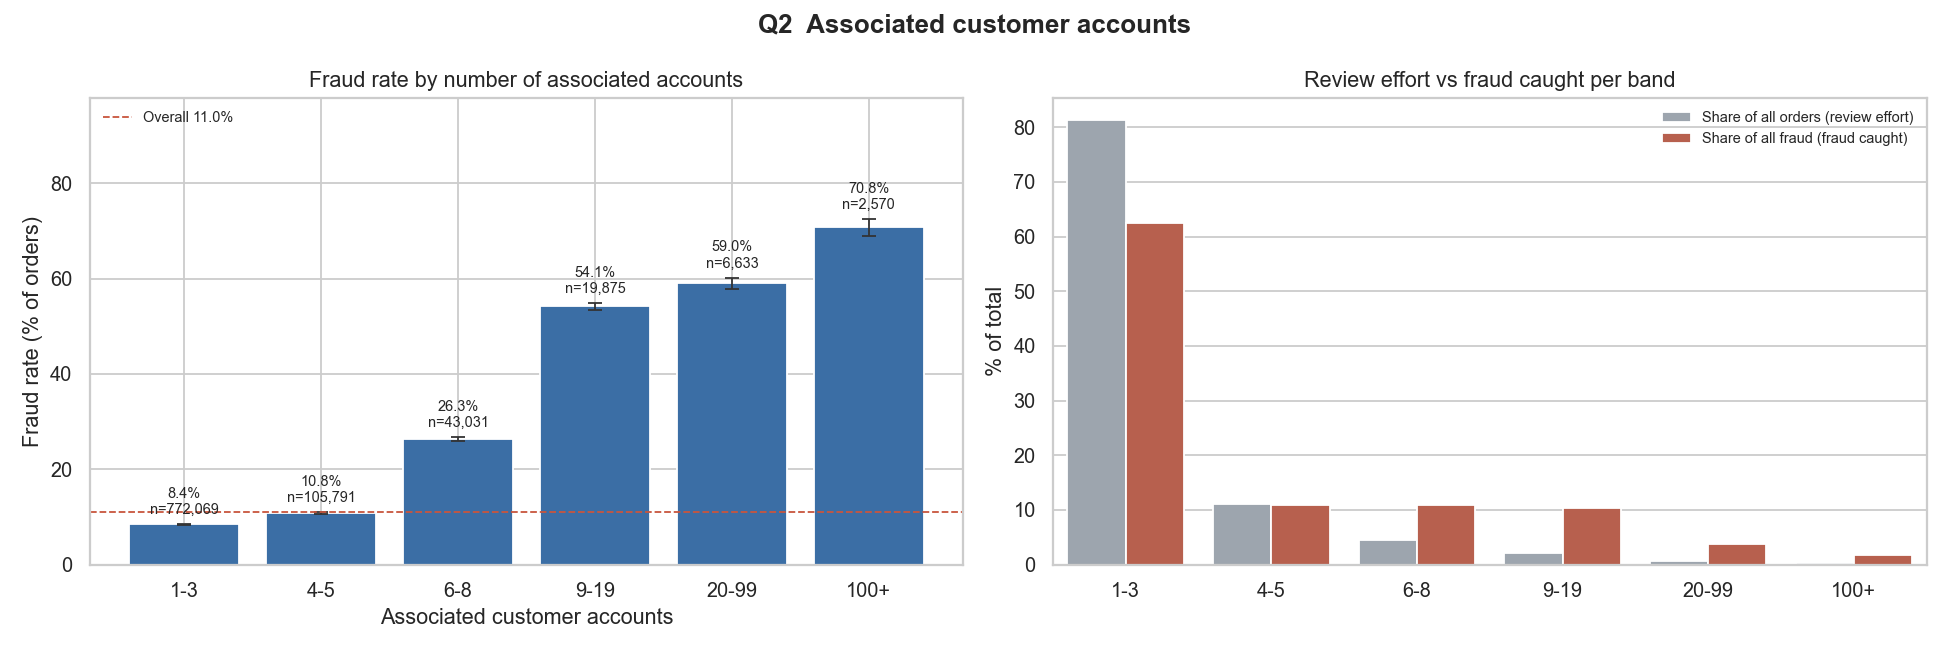

In [6]:
chart("q2_associated_accounts")

In [7]:
print("Review effort vs fraud caught, reviewing the riskiest bands first:")
display(table("q2_review_priority"))
print("Confirmed-fraud accounts with the most associated accounts (review their linked accounts):")
display(table("q2_review_list"))

Review effort vs fraud caught, reviewing the riskiest bands first:


,priority,segment,orders,frauds,fraud_rate_pct,lift,cum_share_of_orders_pct,cum_share_of_fraud_pct
0,1,100+,2570,1819,70.78,6.44,0.27,1.74
1,2,20-99,6633,3912,58.98,5.37,0.97,5.49
2,3,9-19,19875,10761,54.14,4.92,3.06,15.79
3,4,6-8,43031,11334,26.34,2.40,7.59,26.64
4,5,4-5,105791,11416,10.79,0.98,18.73,37.58
5,6,1-3,772069,65191,8.44,0.77,100.00,100.00


Confirmed-fraud accounts with the most associated accounts (review their linked accounts):


,country,country_code,customer_id,num_associated_customers,orders,frauds,fraud_order_value
0,Malaysia,MY,e28fa6f56f,10,61,57,287.78
1,Malaysia,MY,fa69b95123,9,41,41,218.98
2,Malaysia,MY,160b24586b,100,45,36,242.42
3,Bangladesh,BD,575d5d3a0e,21,59,35,118.58
4,Malaysia,MY,2e93ea268d,12,30,28,215.74
5,Bangladesh,BD,8e539349a8,68,26,24,145.52
6,Pakistan,PK,a766d90290,11,28,20,49.92
7,Pakistan,PK,e7e93f8885,66,22,18,302.00
8,Bangladesh,BD,9b692ef44e,20,20,18,55.25
9,Malaysia,MY,45ccad4f8c,17,23,18,109.02


### Q2 insights

- The fraud rate **rises steeply with the number of associated accounts**: 8.4% for customers with 1-3 links, up to **70.8% for 100+ links** (6.44 times the overall rate).
- Reviewing only the bands with at least twice the overall rate (6 or more links) means **7.6% of orders but 26.6% of all fraud, and 38.6% of the reviewed orders are fraud**, compared with 11.0% at random.

**Investigation decision:** yes, linked-account activity should be used when prioritising suspicious accounts. Orders from customers with 6 or more associated accounts should be reviewed first, and the review list shows the confirmed-fraud accounts whose linked accounts should be checked next, since linked accounts may belong to the same fraud network.

## Q3 Does a higher cancellation rate over the last 50 days correspond to a higher fraud rate?

**Investigation decision:** whether unusually frequent order cancellations warrant further investigation.

**Method:** cancellation rate = cancelled orders / orders in the last 50 days, grouped into 0%, >0-10%, >10-20%, >20-30% and >30%. Customers with no orders in the last 50 days cannot have a rate, so they form their own group instead of being counted as 0%. The rate rises steadily up to about 30% and then levels off, so everything above 30% is one band.

A second view combines a high cancellation rate (20% or more) with a high refund rate (20% or more), to check whether using both signals together finds fraud better than either alone.

In [8]:
table("q3_cancellation_bands", ["segment"] + RATE + SHARES)

,segment,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,lift,share_of_orders_pct,share_of_fraud_pct
0,No recent orders,43947,13608,30.96,30.53,31.40,2.82,4.63,13.03
1,0%,645532,60392,9.36,9.29,9.43,0.85,67.95,57.83
2,>0-10%,206909,17526,8.47,8.35,8.59,0.77,21.78,16.78
3,>10-20%,35757,7209,20.16,19.75,20.58,1.83,3.76,6.90
4,>20-30%,8989,2655,29.54,28.60,30.49,2.69,0.95,2.54
5,>30%,8835,3043,34.44,33.46,35.44,3.13,0.93,2.91


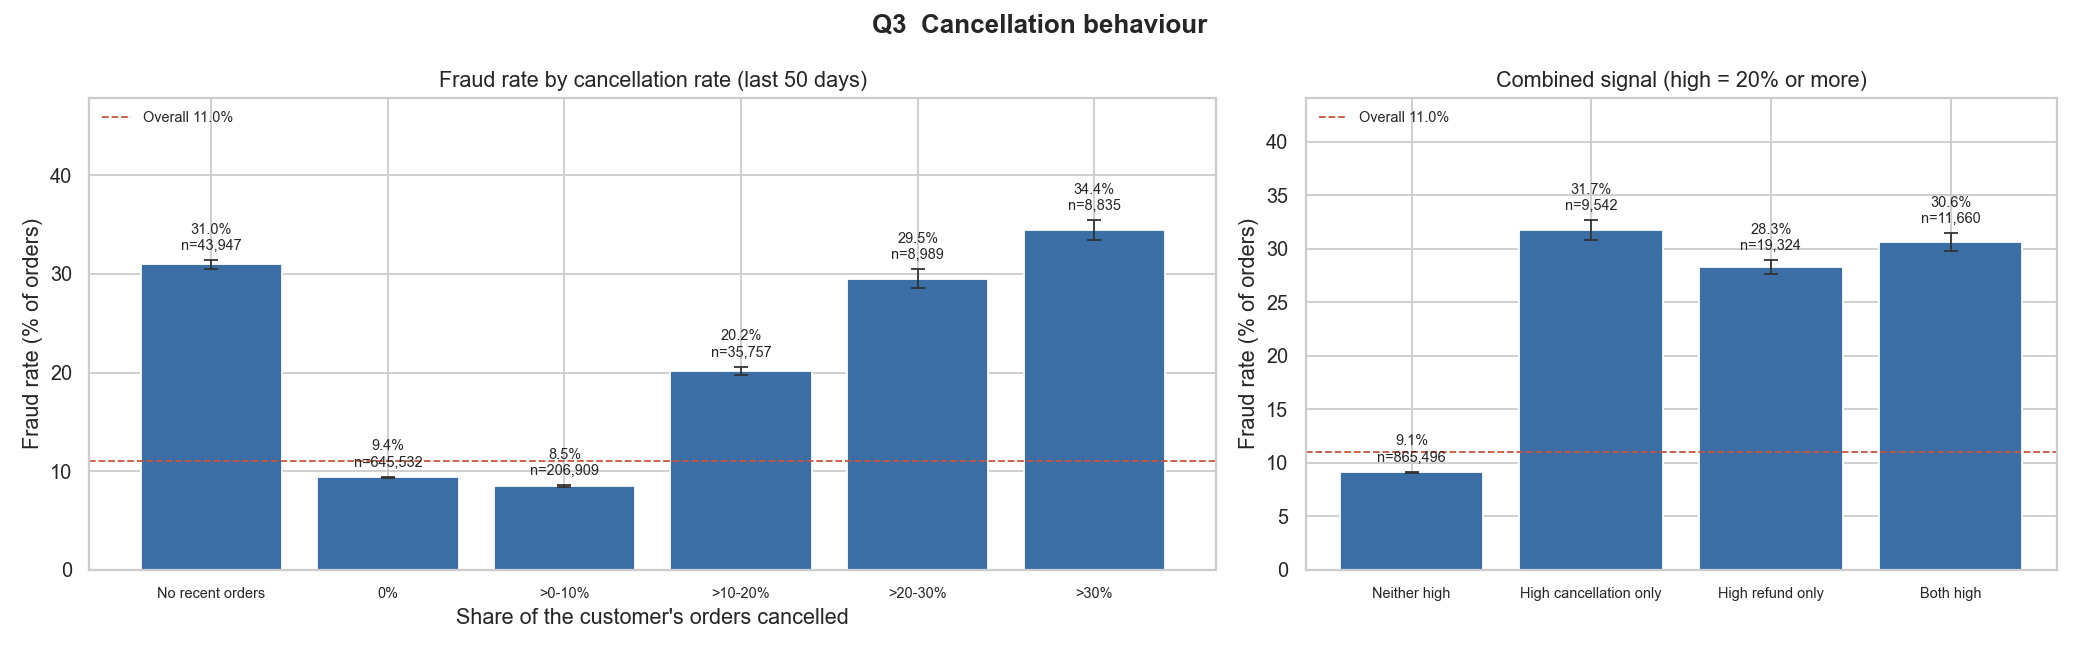

In [9]:
chart("q3_cancellation")

In [10]:
print("Combined cancellation and refund signal:")
display(table("q3_combined_signal", ["signal"] + RATE + SHARES))
print("Review effort vs fraud caught, reviewing the riskiest groups first:")
display(table("q3_review_priority"))

Combined cancellation and refund signal:


,signal,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,lift,share_of_orders_pct,share_of_fraud_pct
0,Neither high,865496,78759,9.10,9.04,9.16,0.83,91.11,75.42
1,High cancellation only,9542,3027,31.72,30.80,32.66,2.89,1.00,2.90
2,High refund only,19324,5470,28.31,27.68,28.95,2.58,2.03,5.24
3,Both high,11660,3569,30.61,29.78,31.45,2.78,1.23,3.42


Review effort vs fraud caught, reviewing the riskiest groups first:


,priority,segment,orders,frauds,fraud_rate_pct,lift,cum_share_of_orders_pct,cum_share_of_fraud_pct
0,1,>30%,8835,3043,34.44,3.13,0.93,2.91
1,2,No recent orders,43947,13608,30.96,2.82,5.56,15.94
2,3,>20-30%,8989,2655,29.54,2.69,6.50,18.49
3,4,>10-20%,35757,7209,20.16,1.83,10.27,25.39
4,5,0%,645532,60392,9.36,0.85,78.22,83.22
5,6,>0-10%,206909,17526,8.47,0.77,100.00,100.00


### Q3 insights

- A higher cancellation rate **goes with a higher fraud rate once it passes about 10%**: customers who cancelled none of their recent orders have 9.4% and those who cancelled up to 10% have 8.5% (an occasional cancellation is normal behaviour), but the rate rises to 20.2% for >10-20%, 29.5% for >20-30% and **34.4% for more than 30%** (3.13 times the overall rate).
- **Customers with no orders in the last 50 days have a 31.0% fraud rate** (2.82 times the overall rate; 4.6% of orders but 13.0% of fraud), even though they placed a labelled order. This may mean the order falls outside the snapshot's 50-day window (cleaning Assumption 19), or that dormant accounts suddenly become active, a known account-takeover pattern.
- Reviewing the three riskiest groups (>30%, no recent orders, >20-30%) means **6.5% of orders and 18.5% of all fraud**, with 31.3% of reviewed orders being fraud.
- Combining the signals adds little: both high is 30.6%, about the same as high cancellation only (31.7%) or high refund only (28.3%).

**Investigation decision:** yes, unusually frequent cancellations warrant further investigation. Customers who cancelled more than 20% of their recent orders, and accounts with no recent orders, should be prioritised; those between 10% and 20% are worth monitoring. Either the cancellation or the refund signal on its own is enough; requiring both would not find more fraud.

## Limitations

- The customer columns (associated accounts and the last-50-day counts) are each customer's **latest snapshot** (the ETL keeps the latest version), and their timing relative to each order is unconfirmed (cleaning Assumption 19). Q2 and Q3 therefore show **associations that help rank accounts for review**, not proof that a behaviour causes fraud.
- Fraud orders in RDS all have a refund value of 0, so money at risk is measured with the order value of fraud orders instead of refunds.
- The latest week in the data (from 8 May 2023) has only 4 days, so its weekly rate is less stable; the latest-4-weeks comparison includes it.
- Findings are based on the labelled orders currently in RDS; they are refreshed whenever the script or the Prefect flow runs after a new batch is loaded.